# Part 2: Relation-based Argument Mining

Ce notebook contient l'implémentation complète du pipeline de fouille d'arguments basé sur les relations, appliqué aux discussions de la plateforme Kialo.

## Objectifs
1. **Scraping & EDA** : Extraction des 250 discussions Kialo les plus actives et analyse exploratoire des données (déséquilibre des classes, longueur des tokens).
2. **Relation Discovery** : Identifier si deux arguments textuels sont sémantiquement liés (classification binaire : Lié / Non Lié).
3. **Relation Classification** : Prédire la polarité de la relation entre deux arguments liés (classification : Attaque / Soutien).

## Méthodologie & Architecture
* **Étape 1 : Préparation des données**
  * Récupération des arbres de débats via la structure fournie.
  * Nettoyage du texte et structuration du dataset en paires séquentielles `(Argument_A, Argument_B, Label)`.
* **Étape 2 : Modélisation**
  * *Approche Cross-Encoder* : Fine-tuning d'un modèle de langage pour classer les paires d'arguments en exploitant l'attention croisée.
  * *Exploration Graphique* : Représentation des débats sous forme de graphes et passage de messages via des réseaux de neurones sur graphes (GNN) pour capturer la topologie structurelle des arguments.
* **Étape 3 : Évaluation & Étude Comparative**
  * Utilisation du **F1-Score Macro** pour pallier le déséquilibre des classes.
  * Comparaison des performances de notre architecture avec des baselines classiques (ex: TF-IDF + modèle linéaire) et les approches existantes dans la littérature.

## Environnement & Dépendances
Pour reproduire ces résultats, assurez-vous que votre environnement Conda est activé avec les packages adéquats installés, notamment `torch` (PyTorch configuré pour l'accélération matérielle) et `transformers` (Hugging Face) pour le chargement et l'ajustement du modèle.

# Extraction des 250 discussions Kialo
## Copy of https://github.com/4mbroise/ADC/blob/main/tool/kialo.ipynb

In [99]:
import pandas as pd
import os
import matplotlib.pyplot as plt


In [100]:
folder = os.listdir("rawData")
print("Nombre de txt :", len(folder))

Nombre de txt : 250


# Data extraction

In [101]:
lignes_df = []

for txt in folder:
    chemin = os.path.join("rawData", txt)
    with open(chemin, encoding="utf-8") as f:
        lignes = f.read().splitlines()

    for i in range(len(lignes) - 1):
        ligne = lignes[i].strip()
        morceaux = ligne.split(" ")          # "1.1.2. Pro:" -> ["1.1.2.", "Pro:"]

        if morceaux[-1] in ["Pro:", "Con:", "Thesis:"]:
            id_arg   = morceaux[0].strip(".")     # "1.1.2"
            relation = morceaux[1].strip(":")     # "Pro"
            arg      = lignes[i + 1].strip()      # le texte sur la ligne suivante
            lignes_df.append([txt, id_arg, relation, arg])

df = pd.DataFrame(lignes_df, columns=["debat", "id", "relation", "arg"])
print(df.shape)
df.head(10)


(101558, 4)


,debat,id,relation,arg
0,according-to-the-bible-salvation-is-by-faith-a...,1,Thesis,"According to the Bible, salvation is by faith ..."
1,according-to-the-bible-salvation-is-by-faith-a...,1.1,Con,Baptism is also required for salvation.
2,according-to-the-bible-salvation-is-by-faith-a...,1.1.1,Pro,"Mark 16:16 [1] says that ""Whoever believes and..."
3,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.1,Con,The portion of Mark where this verse appears i...
4,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.2,Con,This passage may imply that all who believe an...
5,according-to-the-bible-salvation-is-by-faith-a...,1.1.2,Pro,"Galatians 3:27 [3] says that ""all of you who w..."
6,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1,Con,This passage is not necessarily referring to w...
7,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1,Pro,1 Corinthians 12:13 [4] discusses a nonliteral...
8,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.1,Con,The Holy Spirit is closely associated [5] with...
9,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.2,Con,"If baptism is what adds [7] one to the church,..."


# Data Cleaning

In [102]:
# 1. Supprimer les copies "-> See 1.1.2."
df = df[~df["arg"].str.startswith("-> See")]

# 2. Supprimer les références [1], [2], ...
df["arg"] = df["arg"].str.replace(r"\[\d+\]", "", regex=True)

# 3. Supprimer les arguments vides
df = df[df["arg"] != ""]

print(df.shape)
df.head(10)


(95845, 4)


,debat,id,relation,arg
0,according-to-the-bible-salvation-is-by-faith-a...,1,Thesis,"According to the Bible, salvation is by faith ..."
1,according-to-the-bible-salvation-is-by-faith-a...,1.1,Con,Baptism is also required for salvation.
2,according-to-the-bible-salvation-is-by-faith-a...,1.1.1,Pro,"Mark 16:16 says that ""Whoever believes and is..."
3,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.1,Con,The portion of Mark where this verse appears i...
4,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.2,Con,This passage may imply that all who believe an...
5,according-to-the-bible-salvation-is-by-faith-a...,1.1.2,Pro,"Galatians 3:27 says that ""all of you who were..."
6,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1,Con,This passage is not necessarily referring to w...
7,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1,Pro,"1 Corinthians 12:13 discusses a nonliteral, s..."
8,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.1,Con,The Holy Spirit is closely associated with Ch...
9,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.2,Con,"If baptism is what adds one to the church, Ch..."


In [103]:
parents = []
profondeurs = []

for id_arg in df["id"]:
    morceaux = id_arg.split(".")              # "1.1.2" -> ["1", "1", "2"]

    parent = ".".join(morceaux[:-1])          # on enlève le dernier numéro -> "1.1"
    parents.append(parent)

    profondeurs.append(len(morceaux) - 1)     # "1" -> 0, "1.1" -> 1, "1.1.2" -> 2

df["parent"] = parents
df["profondeur"] = profondeurs

df.head(10)


,debat,id,relation,arg,parent,profondeur
0,according-to-the-bible-salvation-is-by-faith-a...,1,Thesis,"According to the Bible, salvation is by faith ...",,0
1,according-to-the-bible-salvation-is-by-faith-a...,1.1,Con,Baptism is also required for salvation.,1,1
2,according-to-the-bible-salvation-is-by-faith-a...,1.1.1,Pro,"Mark 16:16 says that ""Whoever believes and is...",1.1,2
3,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.1,Con,The portion of Mark where this verse appears i...,1.1.1,3
4,according-to-the-bible-salvation-is-by-faith-a...,1.1.1.2,Con,This passage may imply that all who believe an...,1.1.1,3
5,according-to-the-bible-salvation-is-by-faith-a...,1.1.2,Pro,"Galatians 3:27 says that ""all of you who were...",1.1,2
6,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1,Con,This passage is not necessarily referring to w...,1.1.2,3
7,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1,Pro,"1 Corinthians 12:13 discusses a nonliteral, s...",1.1.2.1,4
8,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.1,Con,The Holy Spirit is closely associated with Ch...,1.1.2.1.1,5
9,according-to-the-bible-salvation-is-by-faith-a...,1.1.2.1.1.2,Con,"If baptism is what adds one to the church, Ch...",1.1.2.1.1,5


# Data exploration

Nombre de débats : 250
Nombre d'arguments : 95845
Plus petit débat : 9 arguments
Plus grand débat : 3548 arguments
Médiane : 272.0 arguments
Profondeur max : 34
Longueur moyenne : 25.5 mots
Longueur max : 118 mots
relation
Con       48326
Pro       47031
Thesis      488
Name: count, dtype: int64


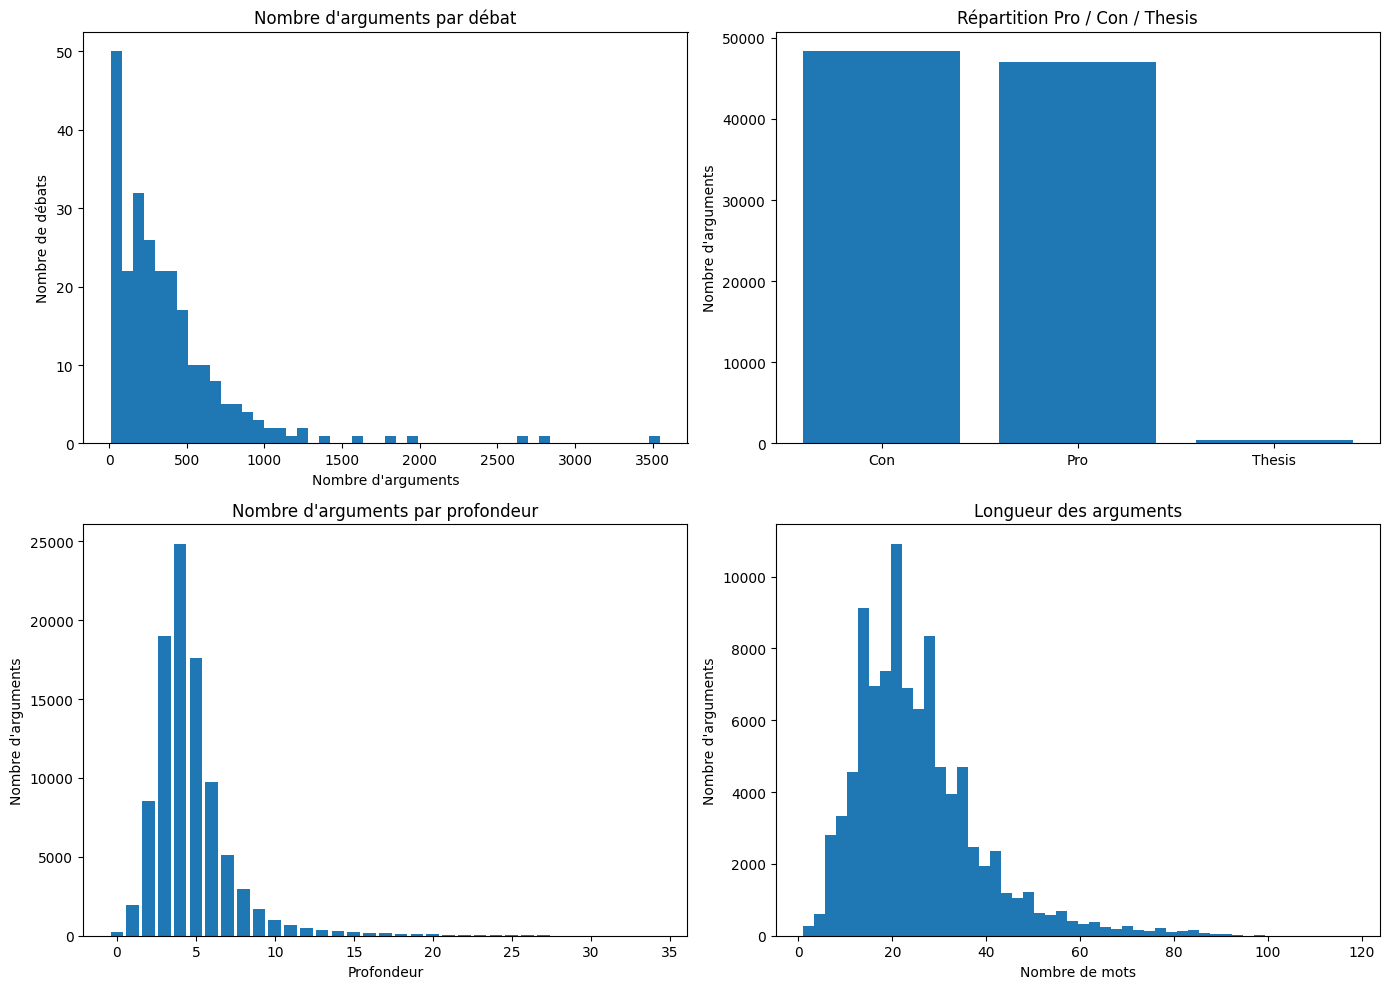

In [ ]:

nb_args = df["debat"].value_counts()
nb_relations = df["relation"].value_counts()
nb_profondeur = df["profondeur"].value_counts().sort_index()

nb_mots = []
for texte in df["arg"]:
    mots = texte.split(" ")
    nb_mots.append(len(mots))
df["nb_mots"] = nb_mots

print("Nombre de débats :", len(nb_args))
print("Nombre d'arguments :", len(df))
print("Plus petit débat :", nb_args.min(), "arguments")
print("Plus grand débat :", nb_args.max(), "arguments")
print("Médiane :", nb_args.median(), "arguments")
print("Profondeur max :", df["profondeur"].max())
print("Longueur moyenne :", round(df["nb_mots"].mean(), 1), "mots")
print("Longueur max :", df["nb_mots"].max(), "mots")
print(nb_relations)


plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.hist(nb_args, bins=50)
plt.title("Nombre d'arguments par débat")
plt.xlabel("Nombre d'arguments")
plt.ylabel("Nombre de débats")

plt.subplot(2, 2, 2)
plt.bar(nb_relations.index, nb_relations.values)
plt.title("Répartition Pro / Con / Thesis")
plt.ylabel("Nombre d'arguments")

plt.subplot(2, 2, 3)
plt.bar(nb_profondeur.index, nb_profondeur.values)
plt.title("Nombre d'arguments par profondeur")
plt.xlabel("Profondeur")
plt.ylabel("Nombre d'arguments")

plt.subplot(2, 2, 4)
plt.hist(df["nb_mots"], bins=50)
plt.title("Longueur des arguments")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre d'arguments")

plt.tight_layout()
plt.show()


## Analyse des données

**Taille du dataset.** Après nettoyage, on obtient 95 845 arguments répartis sur 250 débats en anglais. Les copies (`-> See ...`) et les références (`[1]`, `[2]`...) ont été supprimées.

**Nombre d'arguments par débat.** La distribution est très asymétrique : la médiane est de 272 arguments, mais les débats vont de 9 à 3 548 arguments. Quelques très gros débats représentent une grande partie des données. Pour la Q2, il faudra donc découper train/test **par débat** pour éviter qu'un gros débat se retrouve à la fois dans l'entraînement et dans le test.

**Répartition Pro / Con.** Les classes sont presque équilibrées : 48 326 Con (50,4 %) contre 47 031 Pro (49,1 %). Pour la classification support/attaque, il n'est donc pas nécessaire de rééquilibrer les classes. On compte 488 thèses : plus que 250 car certains débats ont plusieurs thèses.

**Profondeur.** Les débats peuvent aller jusqu'à une profondeur de 34, mais la grande majorité des arguments se situe dans les premiers niveaux de l'arbre. Les arbres sont donc plutôt larges que profonds.

**Longueur des arguments.** Un argument fait en moyenne 25,5 mots et au maximum 118 mots, car Kialo limite la taille des arguments. Pour la Q2, une paire (parent + enfant) dépassera rarement 250 mots : une longueur maximale de 256 tokens suffira pour le modèle.
